# Order Cancellation and Customer Satisfaction EDA

## Purpose
Describe cancellation patterns and customer review outcomes using internal Olist data. Prepare one-row-per-order business data for Chau to use in Stage 3. Hypothesis tests belong to Stage 3 and are not performed here.

## Scope
- Cancellation uses all recorded orders, not only delivered orders.
- Review comparisons use valid delivery labels and selected valid review scores.
- Low review means 1–2 stars; missing scores remain missing.
- Findings are descriptive associations, not causal effects.
- Tables and figures are exported automatically; source datasets remain unchanged.


In [1]:
# Purpose: Load cleaned internal data and create output folders.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/processed").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data/processed"
TABLE_DIR = ROOT / "outputs/tables/cancellation_satisfaction"
FIGURE_DIR = ROOT / "outputs/figures/cancellation_satisfaction"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

orders = pd.read_csv(DATA_DIR / "orders_clean.csv", dtype={"order_id": "string", "customer_id": "string"})
customers = pd.read_csv(DATA_DIR / "customers_clean.csv", dtype={"customer_id": "string"})
reviews = pd.read_csv(DATA_DIR / "reviews_clean.csv", dtype={"order_id": "string", "review_id": "string"})
research = pd.read_csv(DATA_DIR / "research_data.csv", dtype={"order_id": "string"})

def save_table(table, filename, index=True):
    table.to_csv(TABLE_DIR / filename, index=index, encoding="utf-8-sig")

def show_figure(filename):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
print("Project:", ROOT)

Project: c:\Users\LENOVO\OneDrive\Desktop\PTTK\Group5_STAT3013.R11


## 1 Prepare one row per order
All orders are retained for cancellation analysis. Missing delivery labels remain missing. The recorded non-canceled group includes other statuses and is not identical to successful deliveries.

In [2]:
# Purpose: Validate keys and join customer state and delivery labels.
for name, table, key in [("orders", orders, "order_id"), ("customers", customers, "customer_id"), ("research", research, "order_id")]:
    assert table[key].notna().all(), f"Missing key: {name}"
    assert table[key].is_unique, f"Duplicated key: {name}"
assert set(orders["order_id"]) == set(research["order_id"])
assert research["is_late"].dropna().isin([0, 1]).all()
assert orders["order_status"].notna().all()
assert orders["customer_id"].isin(customers["customer_id"]).all()
analysis = orders[["order_id", "customer_id", "order_status", "order_purchase_timestamp"]].merge(
    customers[["customer_id", "customer_state"]], on="customer_id", how="left", validate="many_to_one"
).merge(research[["order_id", "is_late", "delivery_delay_days"]], on="order_id", how="left", validate="one_to_one")
raw_date = analysis["order_purchase_timestamp"]
analysis["order_purchase_timestamp"] = pd.to_datetime(raw_date, errors="coerce")
assert not (raw_date.notna() & analysis["order_purchase_timestamp"].isna()).any()
analysis["purchase_month"] = analysis["order_purchase_timestamp"].dt.to_period("M")
analysis["is_canceled"] = analysis["order_status"].eq("canceled").astype(int)
print("Total orders:", len(analysis))
print("Canceled orders:", analysis["is_canceled"].sum())
print("Missing state:", analysis["customer_state"].isna().sum())

Total orders: 99441
Canceled orders: 625
Missing state: 0


## 2 Cancellation overview
Business question: how common are cancellations, and where should the team investigate further? Rates use all recorded orders in the relevant group.

,orders,percent
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


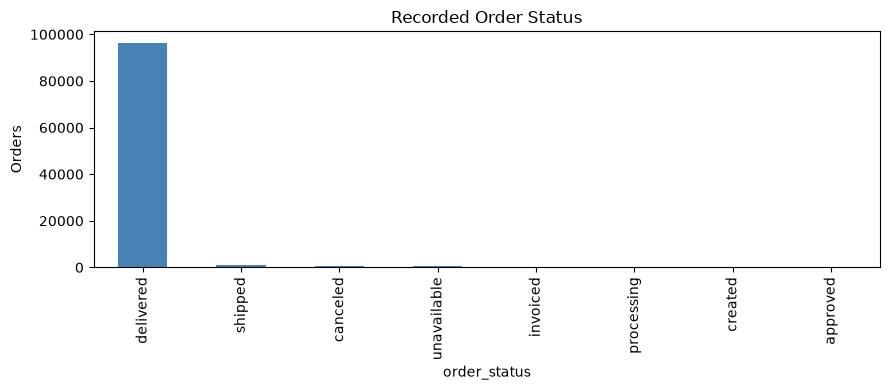

,total_orders,canceled_orders,cancellation_rate_pct,low_sample
purchase_month,,,,
2016-09,4,2,50.0,True
2016-10,324,24,7.41,False
2016-11,0,0,<NA>,True
2016-12,1,0,0.0,True
2017-01,800,3,0.38,False
2017-02,1780,17,0.96,False
2017-03,2682,33,1.23,False
2017-04,2404,18,0.75,False
2017-05,3700,29,0.78,False


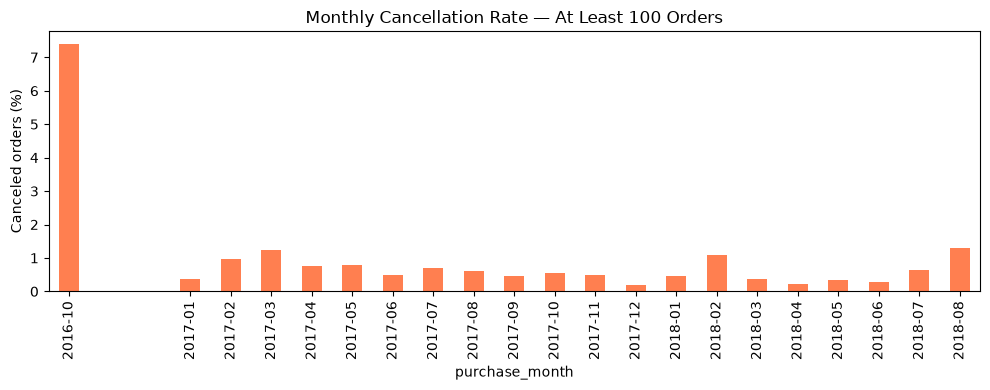

,total_orders,canceled_orders,cancellation_rate_pct,low_sample
customer_state,,,,
RR,46,1,2.17,True
RO,253,3,1.19,False
PI,495,4,0.81,False
SP,41746,327,0.78,False
RJ,12852,86,0.67,False
GO,2020,13,0.64,False
MG,11635,64,0.55,False
MA,747,4,0.54,False
CE,1336,7,0.52,False


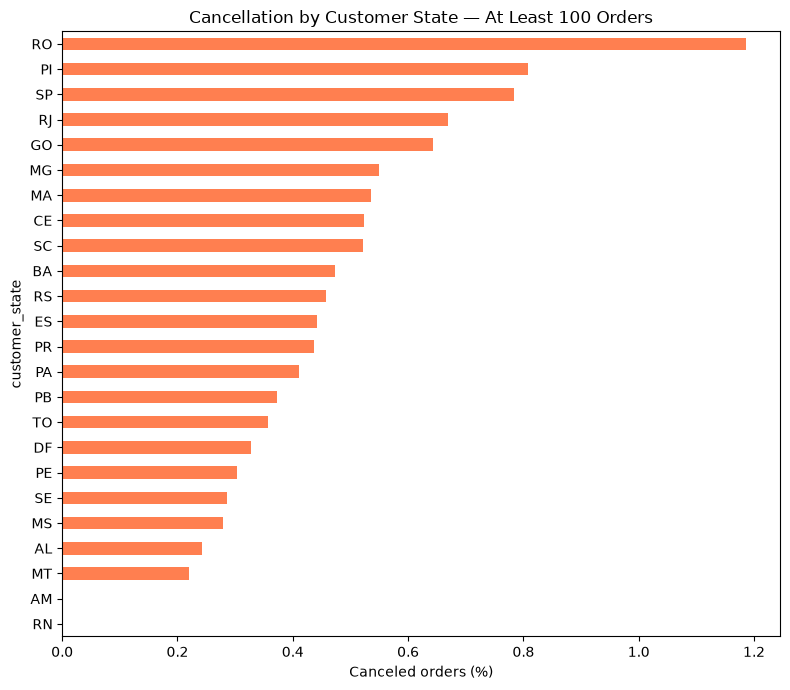

Missing purchase dates: 0


In [3]:
# Purpose: Describe status distribution and cancellation by month and state.
status_summary = analysis["order_status"].value_counts().to_frame("orders")
status_summary["percent"] = status_summary["orders"] / len(analysis) * 100
status_summary.index.name = "order_status"
display(status_summary.round(2))
save_table(status_summary, "status_summary.csv")
status_summary["orders"].plot.bar(figsize=(9, 4), color="steelblue")
plt.ylabel("Orders"); plt.title("Recorded Order Status")
show_figure("order_status.png")

monthly = analysis.groupby("purchase_month").agg(total_orders=("order_id", "size"), canceled_orders=("is_canceled", "sum"))
all_months = pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")
monthly = monthly.reindex(all_months, fill_value=0)
monthly.index.name = "purchase_month"
monthly["cancellation_rate_pct"] = monthly["canceled_orders"] / monthly["total_orders"].replace(0, np.nan) * 100
monthly["low_sample"] = monthly["total_orders"] < 100
save_table(monthly, "monthly_cancellation.csv")
display(monthly.round(2))
monthly.loc[monthly["total_orders"] >= 100, "cancellation_rate_pct"].plot.bar(figsize=(10, 4), color="coral")
plt.ylabel("Canceled orders (%)"); plt.title("Monthly Cancellation Rate — At Least 100 Orders")
show_figure("monthly_cancellation.png")

state_summary = analysis.groupby("customer_state", dropna=False).agg(total_orders=("order_id", "size"), canceled_orders=("is_canceled", "sum"))
state_summary["cancellation_rate_pct"] = state_summary["canceled_orders"] / state_summary["total_orders"] * 100
state_summary["low_sample"] = state_summary["total_orders"] < 100
state_summary = state_summary.sort_values("cancellation_rate_pct", ascending=False)
display(state_summary.round(2)); save_table(state_summary, "state_cancellation.csv")
state_summary.loc[~state_summary["low_sample"], "cancellation_rate_pct"].sort_values().plot.barh(figsize=(8, 7), color="coral")
plt.xlabel("Canceled orders (%)"); plt.title("Cancellation by Customer State — At Least 100 Orders")
show_figure("state_cancellation.png")
print("Missing purchase dates:", analysis["order_purchase_timestamp"].isna().sum())

## 3 Prepare customer satisfaction data
Select the earliest answered review per order; break timestamp ties by review_id and put missing dates last. If all answer dates for an order are missing, this rule is deterministic but does not establish its true first review. Do not choose reviews based on their score. A missing score is not zero stars.

Low review is defined as 1–2 stars, versus 3–5 stars. This is a stated analysis convention.

In [4]:
# Purpose: Audit review records and select one review per order.
assert reviews["order_id"].notna().all()
assert reviews["order_id"].isin(orders["order_id"]).all()
assert not reviews.duplicated(["review_id", "order_id"]).any()
reviews["review_score"] = pd.to_numeric(reviews["review_score"], errors="raise")
assert reviews["review_score"].dropna().isin([1, 2, 3, 4, 5]).all()
raw_answer = reviews["review_answer_timestamp"]
reviews["review_answer_timestamp"] = pd.to_datetime(raw_answer, errors="coerce")
assert not (raw_answer.notna() & reviews["review_answer_timestamp"].isna()).any()
review_counts = reviews.groupby("order_id").size()
review_audit = pd.DataFrame({"check": ["Review rows", "Orders with multiple reviews", "Missing answer timestamps"],
    "value": [len(reviews), review_counts.gt(1).sum(), reviews["review_answer_timestamp"].isna().sum()]})
display(review_audit); save_table(review_audit, "review_audit.csv", False)
first_review = reviews.sort_values(["review_answer_timestamp", "review_id"], na_position="last").drop_duplicates("order_id")
satisfaction = analysis.merge(first_review[["order_id", "review_id", "review_score", "review_answer_timestamp"]], on="order_id", how="left", validate="one_to_one")
satisfaction["low_review"] = satisfaction["review_score"].le(2).astype("Int64").mask(satisfaction["review_score"].isna())
assert satisfaction["order_id"].is_unique and len(satisfaction) == len(orders)
save_table(satisfaction, "order_business_analysis.csv", False)

,check,value
0,Review rows,99224
1,Orders with multiple reviews,547
2,Missing answer timestamps,0


,orders,percent
review_score,,
1,11346,11.50
2,3130,3.17
3,8120,8.23
4,19053,19.31
5,57024,57.79


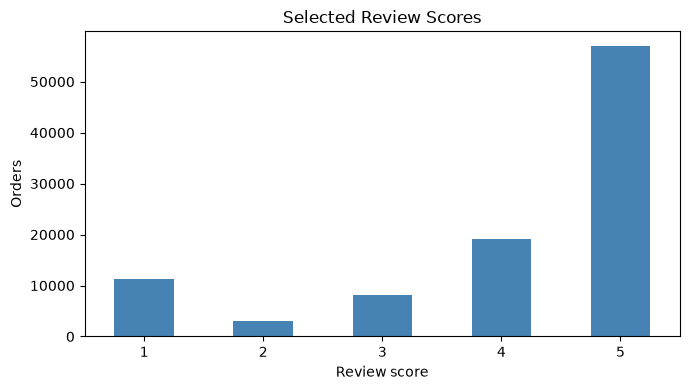

,labeled_orders,reviewed_orders,missing_reviews,missing_review_pct
delivery_label,,,,
Not Late,89936,89443,493,0.55
Late,6534,6381,153,2.34


,reviewed_orders,low_reviews,mean_score,median_score,low_review_rate_pct
delivery_label,,,,,
Not Late,89443,8283,4.29,5.0,9.26
Late,6381,3979,2.27,1.0,62.36


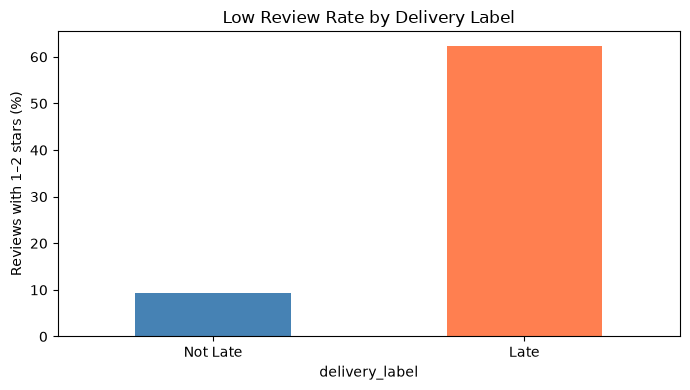

In [5]:
# Purpose: Describe score distribution and review coverage by delivery label.
score_summary = satisfaction["review_score"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0).to_frame("orders")
score_summary.index.name = "review_score"
score_summary["percent"] = score_summary["orders"] / score_summary["orders"].sum() * 100
display(score_summary.round(2)); save_table(score_summary, "review_score_summary.csv")
score_summary["orders"].plot.bar(figsize=(7, 4), color="steelblue", rot=0)
plt.xlabel("Review score"); plt.ylabel("Orders"); plt.title("Selected Review Scores")
show_figure("review_scores.png")

labeled = satisfaction[satisfaction["is_late"].isin([0, 1])].copy()
labeled["delivery_label"] = labeled["is_late"].map({0: "Not Late", 1: "Late"})
coverage = labeled.groupby("delivery_label").agg(labeled_orders=("order_id", "size"), reviewed_orders=("review_score", "count")).reindex(["Not Late", "Late"])
coverage["missing_reviews"] = coverage["labeled_orders"] - coverage["reviewed_orders"]
coverage["missing_review_pct"] = coverage["missing_reviews"] / coverage["labeled_orders"] * 100
display(coverage.round(2)); save_table(coverage, "review_coverage_by_label.csv")
review_sample = labeled.dropna(subset=["review_score"]).copy()
review_summary = review_sample.groupby("delivery_label").agg(reviewed_orders=("order_id", "size"), low_reviews=("low_review", "sum"), mean_score=("review_score", "mean"), median_score=("review_score", "median")).reindex(["Not Late", "Late"])
review_summary["low_review_rate_pct"] = review_summary["low_reviews"] / review_summary["reviewed_orders"] * 100
display(review_summary.round(2)); save_table(review_summary, "satisfaction_by_delivery_label.csv")
review_summary["low_review_rate_pct"].plot.bar(figsize=(7, 4), color=["steelblue", "coral"], rot=0)
plt.ylabel("Reviews with 1–2 stars (%)"); plt.title("Low Review Rate by Delivery Label")
show_figure("low_review_by_delivery_label.png")

## 4 Business interpretation and handoff

- Cancellation: inspect groups with both enough orders and notable cancellation rates. The data do not identify cancellation reasons or timing. Non-canceled is not identical to successfully delivered.
- Satisfaction: compare the share of low reviews between delivery groups and report review coverage. Selected reviews reflect overall purchase experience, not delivery alone.
- First answered review selection is a convention. Missing answer timestamps and multiple-review counts are reported in review_audit.csv.
- The monthly and state charts use a minimum of 100 orders as a display rule, not a significance threshold. Boundary months may be incomplete.
- No hypothesis tests, p-values or statistical-significance claims are included. Chau will define and perform those analyses in Stage 3.
- Review scores and recorded final outcomes must not be used as purchase-time predictors.



In [6]:
# Purpose: Export descriptive analysis data for Stage 3.
save_table(analysis[["order_id", "customer_state", "purchase_month", "order_status", "is_canceled"]], "cancellation_analysis_data.csv", False)
save_table(review_sample[["order_id", "is_late", "review_score", "low_review"]], "satisfaction_analysis_data.csv", False)

# Purpose: Print business summaries and list exported outputs.
print(f"Recorded cancellation rate: {analysis['is_canceled'].mean() * 100:.2f}%")
for group, row in review_summary.iterrows():
    print(f"{group}: {int(row['low_reviews']):,}/{int(row['reviewed_orders']):,} low reviews ({row['low_review_rate_pct']:.2f}%)")
print("CSV files:", len(list(TABLE_DIR.glob("*.csv"))))
print("PNG figures:", len(list(FIGURE_DIR.glob("*.png"))))
print("Tables:", TABLE_DIR)
print("Figures:", FIGURE_DIR)

Recorded cancellation rate: 0.63%
Not Late: 8,283/89,443 low reviews (9.26%)
Late: 3,979/6,381 low reviews (62.36%)
CSV files: 10
PNG figures: 5
Tables: c:\Users\LENOVO\OneDrive\Desktop\PTTK\Group5_STAT3013.R11\outputs\tables\cancellation_satisfaction
Figures: c:\Users\LENOVO\OneDrive\Desktop\PTTK\Group5_STAT3013.R11\outputs\figures\cancellation_satisfaction
